# Лабораторна робота №5. Алгоритми ковзного вікна для обробки Time Series
Дані: щомісячне виробництво електроенергії (Electric_Production, 1985–2018). Модель — SARIMA (групи вимог 1 і 2).

## 1. Завантаження даних

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("archive/Electric_Production.csv")

In [3]:
df.columns = ['date', 'consumption']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         397 non-null    str    
 1   consumption  397 non-null    float64
dtypes: float64(1), str(1)
memory usage: 6.3 KB


In [5]:
df['date'] = pd.to_datetime(df['date'])

In [6]:
df.head(15)

,date,consumption
0,1985-01-01,72.5052
1,1985-02-01,70.6720
2,1985-03-01,62.4502
3,1985-04-01,57.4714
4,1985-05-01,55.3151
5,1985-06-01,58.0904
6,1985-07-01,62.6202
7,1985-08-01,63.2485
8,1985-09-01,60.5846
9,1985-10-01,56.3154


## 2. Дослідження властивостей даних
Графік ряду, STL-декомпозиція і статистичні характеристики.

In [7]:
import matplotlib.pyplot as plt

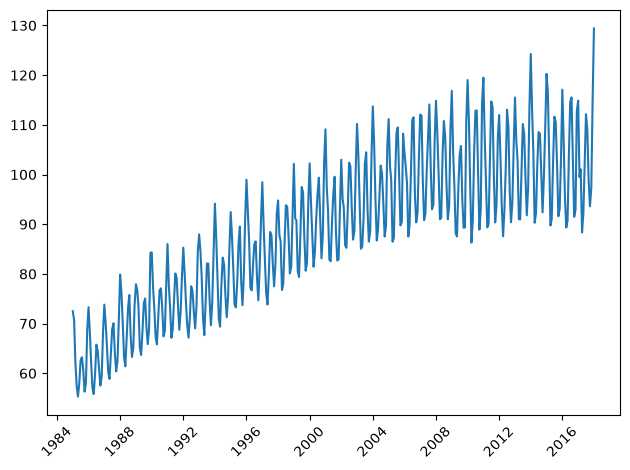

In [8]:
plt.plot(df['date'], df['consumption'])
plt.xticks(rotation=45)
plt.tight_layout()

In [9]:
import sys
import os
sys.path.append(os.path.abspath('..')) 

from lab4.time_series_analysis.decomposition import *

In [10]:
Y = df['consumption']

In [11]:
decomposed = decompose(Y, 12, 3, True)

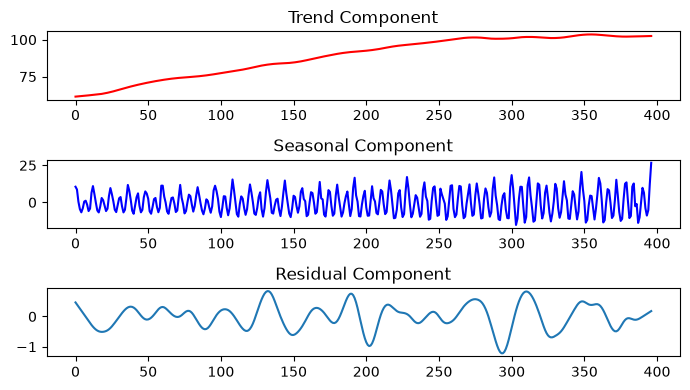

In [12]:
plot_decomposition(decomposed)

text
кількість елементів вбірки= 397
матиматичне сподівання ВВ= -0.43903892649852594
дисперсія ВВ = 61.65867176660544
СКВ ВВ= 7.8523035961815335 



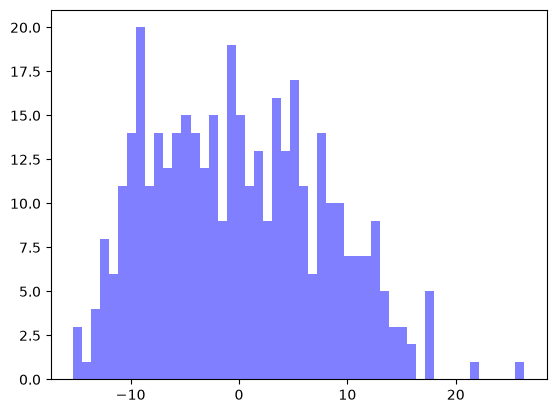

In [13]:
from lab4.time_series_analysis.stat_analysis import *
ts_stat_characteristics(Y, "text")

## 3. Модель SARIMA
Ряд має тренд і річну сезонність (s = 12), тому використовуємо сезонну ARIMA з диференціюванням d = D = 1. Початкові параметри: (1,1,1)×(0,1,1,12).

In [14]:
s = 12

In [15]:
p = 1
q = 1
P = 0 
Q = 1
d = 1
D = 1

Послідовний поділ: 80% даних — навчання, 20% — тест.

In [16]:
train_size = int(len(df) * 0.8)
train, test = df['consumption'][:train_size], df['consumption'][train_size:]

In [17]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(train,
                 order=(p, d, q),
                 seasonal_order=(P, D, Q, s))
results = model.fit()
print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                        consumption   No. Observations:                  317
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -675.030
Date:                            Tue, 22 Sep 2026   AIC                           1358.061
Time:                                    20:53:42   BIC                           1372.929
Sample:                                         0   HQIC                          1364.009
                                            - 317                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5059      0.058      8.719      0.000       0.392       0.620
ma.L1         -0.9540      0.020   

## 4. Екстраполяція на 0.5, 1.0, 1.5 і 2 інтервали спостереження
Для прогнозу за межі спостережень модель перенавчаємо на всьому ряді, щоб прогноз починався одразу після останньої дати.

In [18]:
full_model = SARIMAX(df['consumption'],
                     order=(p, d, q),
                     seasonal_order=(P, D, Q, s))
full_results = full_model.fit(disp=False)

def extrapolate(df, k, results):
    ex_n = int(k * len(df))
    extrapolated_dates = pd.date_range(start=df['date'].iloc[-1] + pd.DateOffset(months=1),
                                       periods=ex_n, freq='MS')
    pred = results.get_forecast(steps=ex_n)
    plt.figure(figsize=(12, 4))
    plt.plot(df['date'], df['consumption'], label='Реальні дані')
    plt.plot(extrapolated_dates, pred.predicted_mean.values, label=f'Прогноз ({k} інтервалу)')
    plt.legend()
    plt.show()

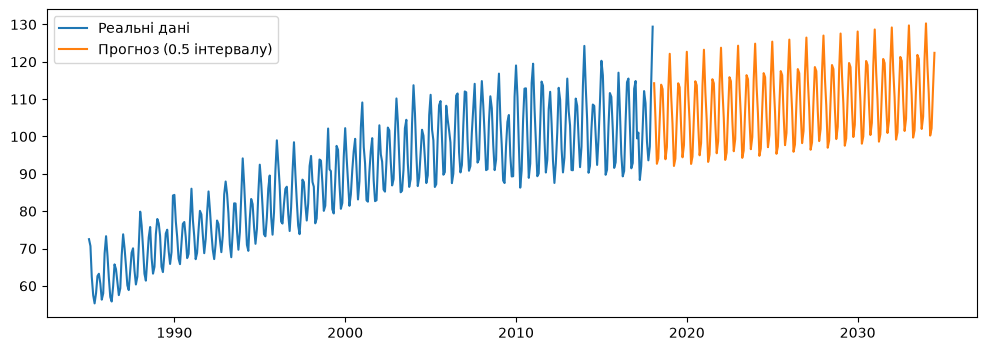

In [19]:
extrapolate(df, 0.5, full_results)

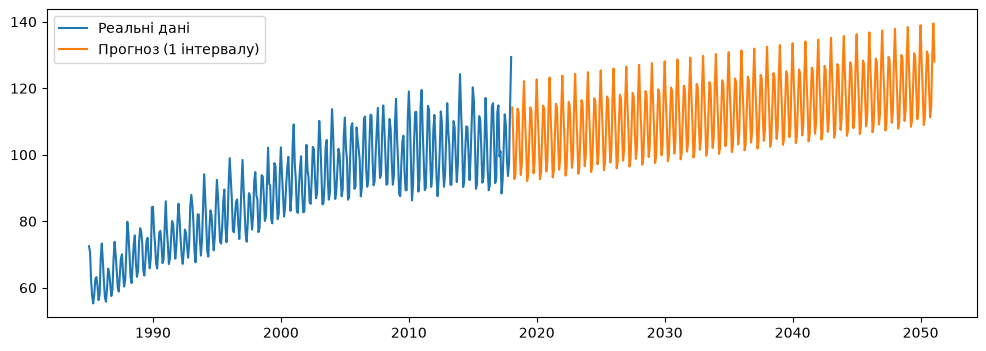

In [20]:
extrapolate(df, 1, full_results)

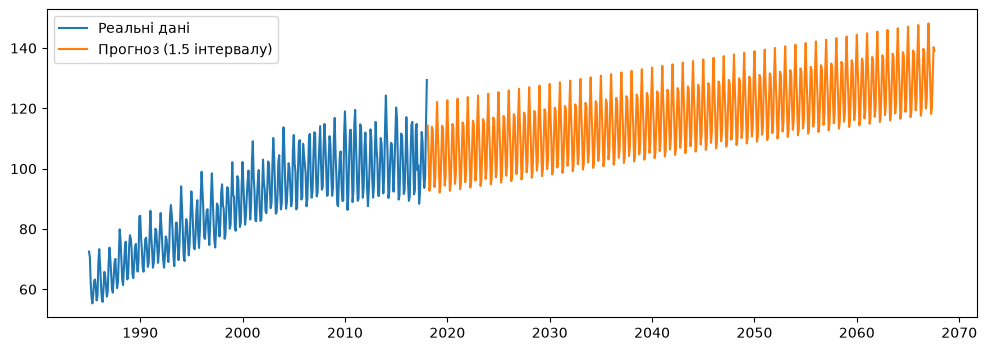

In [21]:
extrapolate(df, 1.5, full_results)

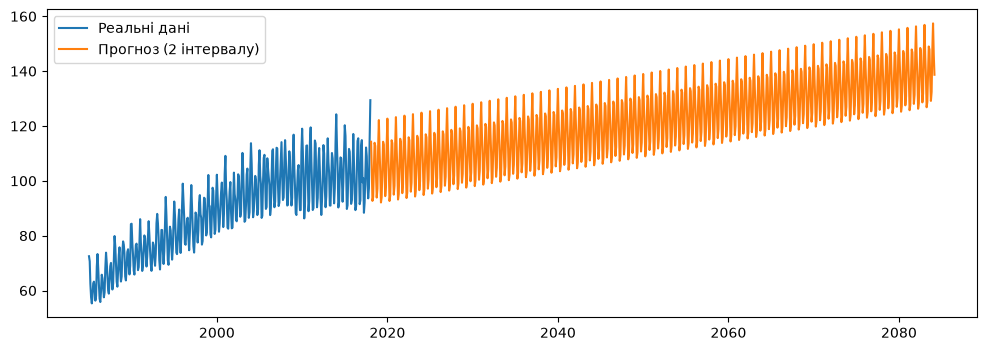

In [22]:
extrapolate(df, 2, full_results)

## 5. Якість моделі на тестовій вибірці
Метрики MAE, RMSE, R² і 95% довірчий інтервал прогнозу.

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
def test_model(results, test):
    test_pred = results.get_forecast(steps=len(test))
    forecast_mean_test = test_pred.predicted_mean
    conf_int_test = test_pred.conf_int()
    
    mae = mean_absolute_error(test, forecast_mean_test)
    rmse = np.sqrt(mean_squared_error(test, forecast_mean_test))
    r2 = r2_score(test, forecast_mean_test)

    print(f"Mae: {mae},\nRMSE: {rmse} \nR2 score: {r2}")

    plt.figure(figsize=(12, 5))
    plt.plot(train.index, train, label='Train')
    plt.plot(test.index, test, label='Test (реальні дані)', color='black')
    plt.plot(test.index, forecast_mean_test, label='Прогноз', color='red')
    plt.fill_between(test.index, conf_int_test.iloc[:,0], conf_int_test.iloc[:,1],
                      color='pink', alpha=0.3, label='95% ДІ')
    plt.legend()
    plt.tight_layout()
    plt.show()

Mae: 3.5580369104080534,
RMSE: 4.358575689588706 
R2 score: 0.7923453639614393


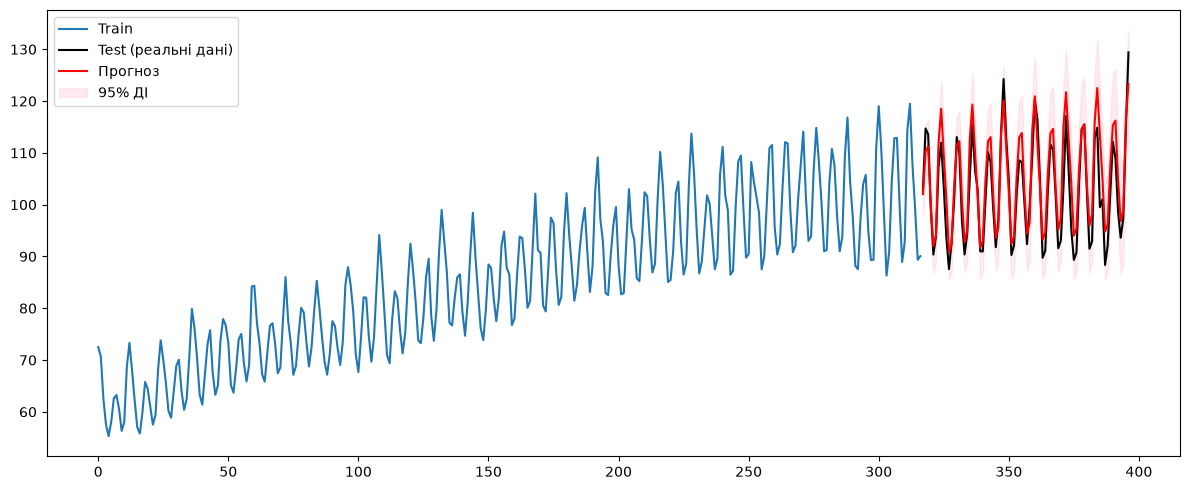

In [24]:
test_model(results, test)

## 6. Оптимізація параметрів
Порядки p і P підбираємо за графіками ACF/PACF сезонно-диференційованого ряду.

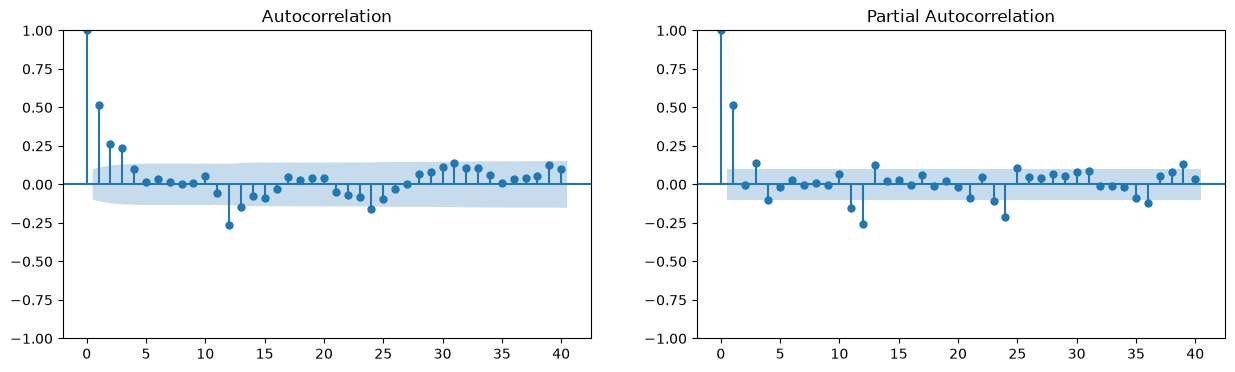

In [25]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

stationary_series = df['consumption'].diff(12).dropna()  
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(stationary_series, ax=axes[0], lags=40)
plot_pacf(stationary_series, ax=axes[1], lags=40)
plt.show()

In [26]:
p = 3
P = 3
q = 1
Q = 1


In [27]:
model2 = SARIMAX(train,
                 order=(p, d, q),
                 seasonal_order=(P, D, Q, s))
results2 = model2.fit()
print(results2.summary())

                                     SARIMAX Results                                      
Dep. Variable:                        consumption   No. Observations:                  317
Model:             SARIMAX(3, 1, 1)x(3, 1, 1, 12)   Log Likelihood                -669.953
Date:                            Tue, 22 Sep 2026   AIC                           1357.906
Time:                                    20:53:45   BIC                           1391.360
Sample:                                         0   HQIC                          1371.289
                                            - 317                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5572      0.062      8.925      0.000       0.435       0.680
ar.L2         -0.1158      0.064   

Mae: 3.248667151972531,
RMSE: 4.037432859513143 
R2 score: 0.8218183100358765


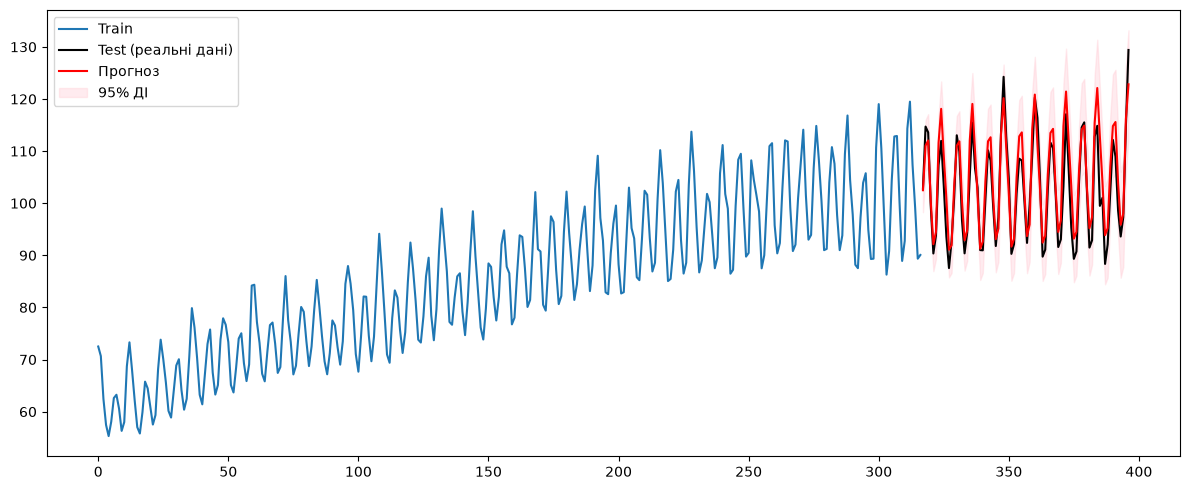

In [28]:
test_model(results2, test)

## 7. Порівняння зі статистичним навчанням (МНК)
Степінь полінома обираємо методом ліктя, модель навчаємо на тій самій тренувальній вибірці.

In [29]:
import numpy as np
import matplotlib.pyplot as plt

from lab4.time_series_analysis.synthetic_sqaure_model import plot_elbow, LSM

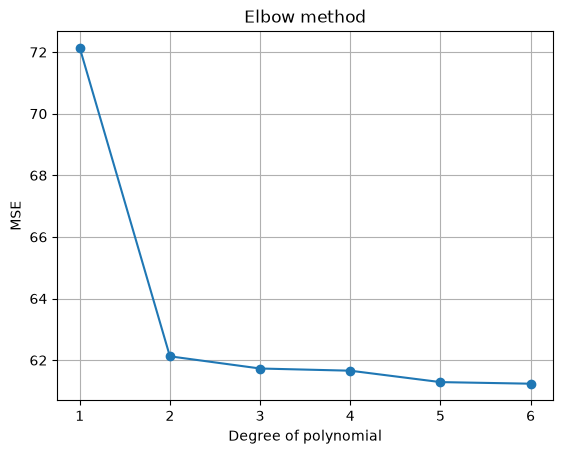

[np.float64(72.14222510599649),
 np.float64(62.12535363349953),
 np.float64(61.729768327973275),
 np.float64(61.65867176660542),
 np.float64(61.28847570254451),
 np.float64(61.236747793017024)]

In [30]:
plot_elbow(Y)

In [31]:
_, c1, c2, c3 = LSM(train)

Регресійна модель:
y(t) =  60.4440108781223  +  0.20082216943116504  * t  +  -0.00020479169444612044  * t^2


In [32]:
def square_model(t, c1, c2, c3):
    return c1 + c2 * t + c3 * t ** 2
stat_model = lambda t : square_model(t, c1, c2, c3)

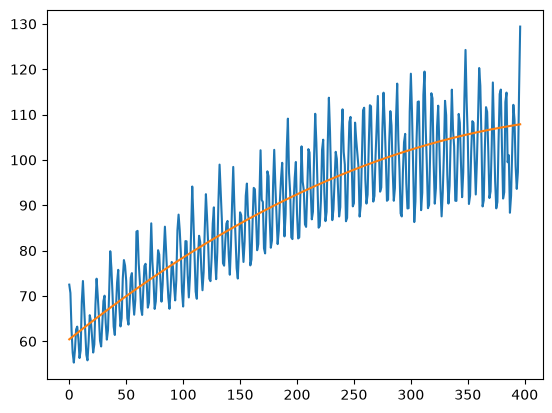

In [33]:
plt.plot(df.index, Y)
plt.plot(df.index, stat_model(df.index) )
plt.show()

In [34]:
pred_stat_model = stat_model(test.index)

Mae: 8.587790295168608,
RMSE: 10.08627080627202 
R2 score: -0.11202281033209505


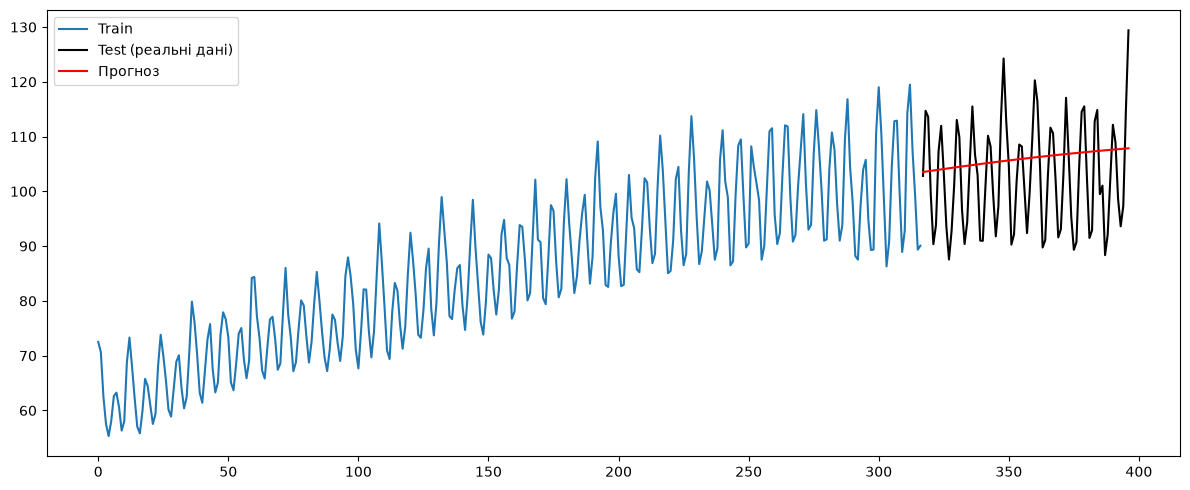

In [35]:
mae = mean_absolute_error(test, pred_stat_model)
rmse = np.sqrt(mean_squared_error(test, pred_stat_model))
r2 = r2_score(test, pred_stat_model)

print(f"Mae: {mae},\nRMSE: {rmse} \nR2 score: {r2}")

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Test (реальні дані)', color='black')
plt.plot(test.index, pred_stat_model, label='Прогноз', color='red')
plt.legend()
plt.tight_layout()
plt.show()

## Висновки та рекомендації
Оптимізація параметрів за ACF/PACF покращила SARIMA: MAE зменшилася з 3.56 до 3.25, R² зріс з 0.79 до 0.82. МНК-модель (поліном 2-го степеня) на тих самих даних дала MAE 8.59 і R² < 0, тобто гірше за просте середнє, бо описує лише тренд і не враховує сезонність. Тому для рядів із вираженою сезонністю та автокореляцією доцільні методи ковзного вікна (ARIMA/SARIMA), а МНК-поліноми — для гладких трендових рядів без сезонності. Довгострокова екстраполяція (1.5–2 інтервали) лише повторює сезонний патерн з лінійним трендом, тому її слід сприймати як орієнтовну.